In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures, SplineTransformer
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import root_mean_squared_error

import os
os.chdir('/Users/lior/DS6021/DS6021_F26/data')
#claude was used to clean code in some sections

(392, 9)


In [2]:
bike = pd.read_csv("bike-sharing-daily.csv")
Xb, yb = bike[["temp"]], bike["cnt"]
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.2, random_state=42)
bike_models = {
    "A: Linear": make_pipeline(LinearRegression()),
    "B: Poly deg 9": make_pipeline(StandardScaler(), PolynomialFeatures(9, include_bias=False), LinearRegression()),
    "C: Spline 7 knots": make_pipeline(SplineTransformer(degree=3, n_knots=7, knots="quantile"), LinearRegression()),
}
for m in bike_models.values(): m.fit(Xb_tr, yb_tr)

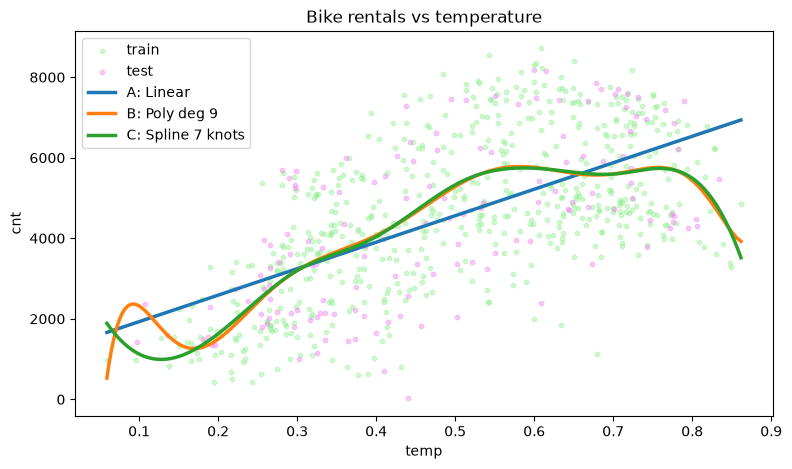

In [8]:
grid = pd.DataFrame({"temp": np.linspace(Xb.temp.min(), Xb.temp.max(), 300)})
plt.figure(figsize=(9, 5))
plt.scatter(Xb_tr, yb_tr, s=10, alpha=0.4, label="train", color="lightgreen")
plt.scatter(Xb_te, yb_te, s=10, alpha=0.4, color="violet", label="test")
for name, m in bike_models.items():
    plt.plot(grid, m.predict(grid), lw=2.5, label=name)
plt.xlabel("temp"); 
plt.ylabel("cnt"); 
plt.legend(); 
plt.title("Bike rentals vs temperature"); 
plt.show()

The linear line cant read the fact that the amount of rentals rise with the temperatures, but dip when it reaches the highest temperatures. Line B and C are almost similar other than the fact the ends of the lines.

In [11]:
rows = []
for name, m in bike_models.items():
    rows.append({"model": name, "test RMSE": root_mean_squared_error(yb_te, m.predict(Xb_te)),
                 "train RMSE": root_mean_squared_error(yb_tr, m.predict(Xb_tr))})
bike_tbl = pd.DataFrame(rows).set_index("model");
print(bike_tbl.round(1))


                   test RMSE  train RMSE
model                                   
A: Linear             1546.3      1497.7
B: Poly deg 9         1531.6      1379.3
C: Spline 7 knots     1532.4      1380.6


2a

Model B has the smallest training RMSE with a value of 1379.3 as well as the smallest test RMSE with a value of 1531.6. Model A has the highest values so it is the worst for both RMSE's.

2b

Not really because going from A to any of the other models lowers the training RMSE from 1498 to 1380, but the test RMSE lowers by a little amount. B and C are incredibly similar when it comes to both of their training RMSEs which doesnt say anything about the error since they both have such small differences.

2c

Model A is underfitted because its too simple for a curved pattern and models B and C are overfitted since the test RMSE and the train RMSE have a big gap in between. 

In [12]:
#3

bike_tbl["5-fold RMSE"] = [np.sqrt(-cross_val_score(m, Xb, yb, cv=KFold(5, shuffle=True, random_state=42),scoring="neg_mean_squared_error").mean()) for m in bike_models.values()]
print(bike_tbl.round(1))

                   test RMSE  train RMSE  5-fold RMSE
model                                                
A: Linear             1546.3      1497.7       1511.0
B: Poly deg 9         1531.6      1379.3       1435.5
C: Spline 7 knots     1532.4      1380.6       1427.6


Models B and C are better than model a in the 5 fold. model c is a little bit better than the polynomial. I would say that this gives me more confidence because the values are showing that theres more flexibility since CV uses every row for testing and doesnt rely on a random split.